# Agrupamento de Vinhos com K-Means
### Checkpoint 5 · Parte 2 · Machine Learning & Modelling · FIAP

**Grupo sInApse**

| Nome | RM |
|---|---|
| Silvio Dela Libera Neto | 572632 |
| Thainá Almeida Santos | 569110 |
| Vitor Barbosa Vitorino | 570475 |

Roteiro (segue os itens do enunciado):

- **a)** Introdução: o problema e a solução proposta
- **b)** Pré-processamento: features de classe, nulos, outliers e padronização
- **c)** Ajuste do K-Means
- **d)** Número de grupos: método Elbow (cotovelo) e Silhueta
- **e)** Análise dos grupos: teor alcoólico, acidez, cinzas e o que mais diferencia um grupo do outro
- **Validação**: "abrindo o cofre", como no notebook da aula
- **Conclusão**

## 0. Setup

Usamos só as bibliotecas e funções do notebook da aula de K-Means (`StandardScaler`, `Pipeline`, `KMeans`, `PCA`,
`silhouette_score`, `silhouette_samples`, `adjusted_rand_score`) e da Aula 07 (`SimpleImputer`, `MinMaxScaler`).

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

from sklearn.impute import SimpleImputer                            # tratamento de nulos (Aula 07)
from sklearn.preprocessing import StandardScaler, MinMaxScaler      # padronizar / normalizar (Aula 07)
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA                               # só para visualizar em 2D
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score

warnings.filterwarnings("ignore")
SEED = 42                                    # mesma semente da aula: resultados reproduzíveis
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
pd.set_option("display.max_columns", None)

# Cores das categorias (paleta testada para daltonismo). Cada grupo terá sempre a mesma cor.
CORES_SLOTS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.axisbelow": True})
print("ok")

ok


## a) Introdução: o problema e a solução proposta

**O problema.** A base WINES tem 178 vinhos da mesma região da Itália, descritos por 13 medidas químicas (teor
alcoólico, ácido málico, cinzas, magnésio, fenóis, cor, prolina...). **Não existe coluna-alvo**: ninguém diz a qual
grupo cada vinho pertence. A pergunta é:

> *Existem grupos de vinhos com perfis químicos parecidos? Se sim, o que diferencia um grupo do outro?
> Qual grupo tem mais álcool, qual é o mais ácido, qual tem menos cinzas?*

Como não há `y`, o problema é de **aprendizado não supervisionado**: o objetivo não é prever um rótulo, e sim
**descobrir estrutura** nos dados. Queremos vinhos parecidos no mesmo grupo (**coesão**) e grupos diferentes entre
si (**separação**).

**A solução proposta.** Seguimos o fluxo de segmentação da aula:

1. **Pré-processar** a mesma base da Parte 1: conferir features de classe, nulos, duplicados e outliers;
2. **Padronizar** com `StandardScaler`, porque o K-Means mede semelhança pela distância Euclidiana;
3. **Ajustar o K-Means** (`k-means++`, `n_init=10`) dentro de um `Pipeline`;
4. **Escolher o k** pelo cotovelo (inércia) e pela silhueta;
5. **Ler o perfil** de cada grupo nas unidades originais e dar um nome a cada um.

**O que trazemos da Parte 1 (Estatística).** A análise das duas variáveis da Parte 1 deixou três hipóteses, que
este notebook vai testar:

| Achado da Parte 1 | Hipótese para o K-Means |
|---|---|
| **Teor alcoólico**: simétrico, CV = 6,24% (baixo), mas **bimodal** (modas 12,37 e 13,05; picos em [12 ; 12,5) e [13 ; 14)) | **H1**: os dois picos são grupos de vinhos misturados |
| **Ácido málico**: assimétrico à direita, CV = 47,82% (muito alto), 3 outliers mantidos; 26% dos vinhos passam de 3 g/L | **H2**: o subgrupo acima de 3 g/L aparece como um cluster próprio |
| A acidez varia muito mais que o álcool | **H3**: a acidez é a variável que mais diferencia os grupos |

A base descreve vinhos de **3 cultivares** (tipos de uva). Isso nos dá uma hipótese inicial de k = 3, mas o k é
hiperparâmetro: quem decide é o cotovelo e a silhueta (item d).

## b) Pré-processamento dos dados

### b.1 Carregando a mesma base da Parte 1

In [2]:
# Mesmo arquivo usado na Parte 1 (R). Se o notebook for aberto fora do repositório
# (ex.: Google Colab), o arquivo é lido direto do GitHub do grupo.
CAMINHO_LOCAL = "../parte1_statistical_computing/wine-clustering.csv"
URL_GITHUB = ("https://raw.githubusercontent.com/Vitoriinoo/CP5_ML_SCWR-P_SINAPSE/"
              "main/parte1_statistical_computing/wine-clustering.csv")

vinhos = pd.read_csv(CAMINHO_LOCAL if os.path.exists(CAMINHO_LOCAL) else URL_GITHUB)
print(f"vinhos: {vinhos.shape[0]} | colunas: {vinhos.shape[1]}")
vinhos.head()

vinhos: 178 | colunas: 13


,Alcohol,Malic_Acid,Ash,Ash_Alcanity,Magnesium,Total_Phenols,Flavanoids,Nonflavanoid_Phenols,Proanthocyanins,Color_Intensity,Hue,OD280,Proline
0,14.23,1.71,2.43,15.60,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065
1,13.20,1.78,2.14,11.20,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050
2,13.16,2.36,2.67,18.60,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185
3,14.37,1.95,2.50,16.80,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480
4,13.24,2.59,2.87,21.00,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735


### b.2 Features de classe e seleção de variáveis

O enunciado pede para excluir **features de classe**. A versão do dataset no GitHub (gist do enunciado) traz uma
coluna `Wine` com o cultivar de cada vinho (1, 2 ou 3). Essa coluna é o **gabarito**: se entrasse no K-Means, o
modelo agruparia pela resposta, e não pelas medidas químicas. A versão do Kaggle, que usamos desde a Parte 1, já vem
sem ela. Mesmo assim, o código abaixo a remove caso exista, para o notebook funcionar com as duas versões.

As 13 colunas restantes são medidas químicas do próprio vinho:

| Variável | Significado | Variável | Significado |
|---|---|---|---|
| `Alcohol` | teor alcoólico (% vol.) | `Nonflavanoid_Phenols` | fenóis não flavonoides |
| `Malic_Acid` | ácido málico (g/L): **acidez** | `Proanthocyanins` | proantocianidinas (taninos) |
| `Ash` | cinzas (minerais) | `Color_Intensity` | intensidade de cor |
| `Ash_Alcanity` | alcalinidade das cinzas | `Hue` | tonalidade |
| `Magnesium` | magnésio | `OD280` | absorbância OD280/OD315 (compostos fenólicos) |
| `Total_Phenols` | fenóis totais | `Proline` | prolina (aminoácido) |
| `Flavanoids` | flavonoides | | |

**Por que usar as 13?** Todas são medições contínuas do vinho (não há ID, data nem texto). Sem um `y`, não temos
como provar que uma variável é irrelevante, e cortar variáveis no escuro seria uma escolha arbitrária. Mantemos as
13 e deixamos a padronização dar o **mesmo peso** a cada uma. A dica do enunciado de "simplificar com poucas
features" aparece no item c.1, onde visualizamos o algoritmo só com as duas variáveis da Parte 1, e na validação,
onde comparamos esse cenário simplificado com o modelo completo.

In [3]:
# Remove a coluna de classe (gabarito) se ela existir; na versão do Kaggle não há nada a remover
vinhos = vinhos.drop(columns=["Wine"], errors="ignore")

FEATURES = list(vinhos.columns)
print(f"{len(FEATURES)} features usadas no K-Means:", FEATURES)
print("\ntipos:", vinhos[FEATURES].dtypes.value_counts().to_dict())   # todas numéricas: não precisa de OneHotEncoder

13 features usadas no K-Means: ['Alcohol', 'Malic_Acid', 'Ash', 'Ash_Alcanity', 'Magnesium', 'Total_Phenols', 'Flavanoids', 'Nonflavanoid_Phenols', 'Proanthocyanins', 'Color_Intensity', 'Hue', 'OD280', 'Proline']

tipos: {dtype('float64'): 11, dtype('int64'): 2}


### b.3 Dados nulos e duplicados

In [4]:
nulos = vinhos.isnull().sum()
print("nulos por coluna:", nulos.to_dict())
print(f"\ntotal de nulos: {nulos.sum()} | vinhos duplicados: {vinhos.duplicated().sum()}")

nulos por coluna: {'Alcohol': 0, 'Malic_Acid': 0, 'Ash': 0, 'Ash_Alcanity': 0, 'Magnesium': 0, 'Total_Phenols': 0, 'Flavanoids': 0, 'Nonflavanoid_Phenols': 0, 'Proanthocyanins': 0, 'Color_Intensity': 0, 'Hue': 0, 'OD280': 0, 'Proline': 0}

total de nulos: 0 | vinhos duplicados: 0


**Leitura:** não há valores nulos (o `summary()` da Parte 1 já indicava isso) nem vinhos duplicados. Os 178 vinhos
entram inteiros. Mesmo assim, o modelo final (item d.3) leva um `SimpleImputer(strategy="median")` dentro do
`Pipeline`. Hoje ele não muda nada, mas protege o modelo quando chegar um vinho novo com alguma medida faltando.
Escolhemos a **mediana**, e não a média, porque a Parte 1 mostrou que o ácido málico é assimétrico e tem outliers:
a média dele é "puxada" pelos vinhos muito ácidos.

### b.4 Outliers

In [5]:
# Mesma regra da Parte 1: outlier é o valor fora de [Q1 - 1,5·IQR ; Q3 + 1,5·IQR]
q1, q3 = vinhos[FEATURES].quantile(0.25), vinhos[FEATURES].quantile(0.75)
iqr = q3 - q1
eh_outlier = (vinhos[FEATURES] < q1 - 1.5 * iqr) | (vinhos[FEATURES] > q3 + 1.5 * iqr)

contagem = eh_outlier.sum()
print("outliers por variável:", contagem[contagem > 0].to_dict())
print(f"vinhos com pelo menos um outlier: {eh_outlier.any(axis=1).sum()} de {len(vinhos)}")
print("ácido málico (os 3 da Parte 1):", sorted(vinhos.loc[eh_outlier["Malic_Acid"], "Malic_Acid"].tolist()))

outliers por variável: {'Malic_Acid': 3, 'Ash': 3, 'Ash_Alcanity': 4, 'Magnesium': 4, 'Proanthocyanins': 2, 'Color_Intensity': 4, 'Hue': 1}
vinhos com pelo menos um outlier: 17 de 178
ácido málico (os 3 da Parte 1): [5.51, 5.65, 5.8]


**Decisão: manter os outliers.**

- Na Parte 1 os 3 outliers do ácido málico (5,51; 5,65; 5,80 g/L) foram mantidos por serem medições plausíveis, não
  erros. As demais variáveis seguem a mesma lógica: são vinhos reais com valores altos ou baixos;
- A base é pequena (178 vinhos). Tirar os 17 vinhos com algum outlier descartaria quase 10% dos dados;
- O K-Means usa médias, então é sensível a outliers (slide de limites da aula). Por isso **conferimos no item c.3**
  que tirar esses 17 vinhos não muda os grupos.

### b.5 Padronização

O K-Means mede "parecido" pela distância Euclidiana, $d(a,b)=\sqrt{\sum_j (a_j-b_j)^2}$. Cada variável contribui com
$(a_j-b_j)^2$, e a média desse termo é proporcional à **variância** da variável. Então a % da variância total mostra
quanto cada variável manda na distância (é a mesma medição do slide 5 da aula).

In [6]:
scaler = StandardScaler()
X = scaler.fit_transform(vinhos[FEATURES])      # z = (x - média) / desvio padrão, coluna a coluna

escala = pd.DataFrame({
    "mínimo": vinhos[FEATURES].min(),
    "máximo": vinhos[FEATURES].max(),
    "desvio antes": vinhos[FEATURES].std(ddof=0),
    "% da distância antes": vinhos[FEATURES].var() / vinhos[FEATURES].var().sum() * 100,
    "desvio depois": X.std(axis=0),
    "% da distância depois": X.var(axis=0) / X.var(axis=0).sum() * 100,
}).sort_values("% da distância antes", ascending=False)
escala

,mínimo,máximo,desvio antes,% da distância antes,desvio depois,% da distância depois
Proline,278.00,"1,680.00",314.02,99.77,1.00,7.69
Magnesium,70.00,162.00,14.24,0.21,1.00,7.69
Ash_Alcanity,10.60,30.00,3.33,0.01,1.00,7.69
Color_Intensity,1.28,13.00,2.31,0.01,1.00,7.69
Malic_Acid,0.74,5.80,1.11,0.00,1.00,7.69
Flavanoids,0.34,5.08,1.00,0.00,1.00,7.69
Alcohol,11.03,14.83,0.81,0.00,1.00,7.69
OD280,1.27,4.00,0.71,0.00,1.00,7.69
Total_Phenols,0.98,3.88,0.62,0.00,1.00,7.69
Proanthocyanins,0.41,3.58,0.57,0.00,1.00,7.69


**Leitura:** sem padronizar, a **prolina** (de 278 a 1.680) responde por **99,77%** da distância, e o magnésio por
mais 0,21%. As outras 11 variáveis somam menos de 0,1%. Na prática o K-Means estaria agrupando os vinhos **só pela
prolina**, e teor alcoólico, acidez e cinzas, que são justamente o que o enunciado pergunta, teriam peso zero.
Depois do `StandardScaler`, todas ficam com média 0 e desvio 1, e cada uma pesa 7,69% (1/13).

**Por que `StandardScaler` e não `MinMaxScaler`?** A Aula 07 apresenta os dois e sugere normalizar quando a
distribuição não é Normal, que é o caso do ácido málico (Parte 1). Mesmo assim escolhemos padronizar:

- O `MinMaxScaler` usa só o mínimo e o máximo de cada coluna. Como mantivemos os outliers, um único vinho extremo
  (ácido málico de 5,80, magnésio de 162) definiria a escala inteira e espremeria todos os outros num intervalo
  pequeno. O z-score usa a média e o desvio de todos os vinhos, então depende menos de um ponto só;
- O K-Means não exige dados Normais: o problema dele é só a **escala**. E o `StandardScaler` é o padrão da aula para
  algoritmos baseados em distância.

Na validação, no fim do notebook, conferimos essa escolha com os dois escalonadores.

## c) Ajuste do K-Means

O K-Means procura $k$ centróides que minimizem a **inércia** (soma dos quadrados das distâncias de cada vinho ao
centróide do seu grupo):

$$J=\sum_{c=1}^{k}\;\sum_{x_i\in C_c}\lVert x_i-\mu_c\rVert^2$$

1. **Inicializar** $k$ centróides;
2. **Atribuir** cada vinho ao centróide mais próximo;
3. **Atualizar** cada centróide para a média dos vinhos atribuídos a ele;
4. **Repetir** 2 e 3 até nenhuma atribuição mudar.

### c.1 O algoritmo passo a passo, com as duas variáveis da Parte 1

Seguindo a dica do enunciado de começar simples, usamos primeiro só `Alcohol` e `Malic_Acid` (padronizadas), que
cabem num gráfico 2D. Partimos sempre dos **mesmos** 3 vinhos sorteados como centróides iniciais e deixamos o
algoritmo andar 1, 2, 3 e 8 iterações.

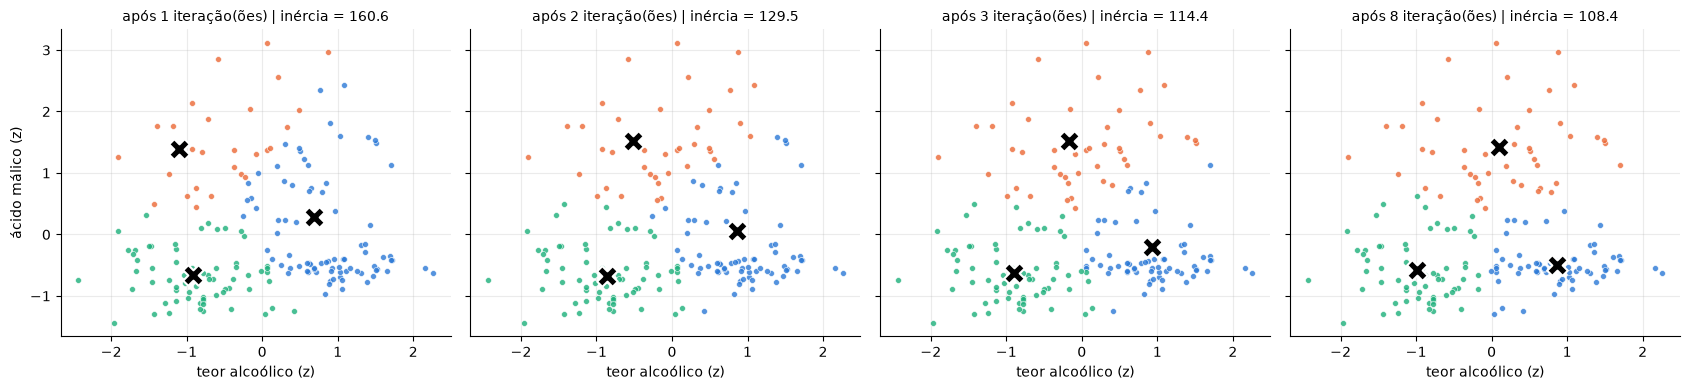

In [7]:
X2 = StandardScaler().fit_transform(vinhos[["Alcohol", "Malic_Acid"]])
inicio = X2[np.random.default_rng(7).choice(len(X2), size=3, replace=False)]   # 3 vinhos sorteados

fig, axes = plt.subplots(1, 4, figsize=(17, 4), sharex=True, sharey=True)
for ax, n_iter in zip(axes, [1, 2, 3, 8]):
    km2 = KMeans(n_clusters=3, init=inicio, n_init=1, max_iter=n_iter, random_state=SEED).fit(X2)
    for c in range(3):
        m = km2.labels_ == c
        ax.scatter(X2[m, 0], X2[m, 1], s=18, alpha=0.8, color=CORES_SLOTS[c], edgecolor="white", linewidth=0.5)
    ax.scatter(km2.cluster_centers_[:, 0], km2.cluster_centers_[:, 1], marker="X", s=220,
               c="black", edgecolor="white", lw=1.5)
    ax.set_title(f"após {n_iter} iteração(ões) | inércia = {km2.inertia_:.1f}", fontsize=10)
    ax.set_xlabel("teor alcoólico (z)")
axes[0].set_ylabel("ácido málico (z)")
plt.tight_layout(); plt.show()

**Leitura:** a cada iteração os centróides (X) se deslocam para o meio dos seus vinhos e a inércia **só cai**
(de 160,6 para 108,4). Por isso o algoritmo sempre converge, mas para um **mínimo local** que depende de onde os
centróides começaram. O scikit-learn protege com dois parâmetros, que usamos daqui em diante:

- `init="k-means++"` (padrão): sorteia os centróides iniciais longe uns dos outros;
- `n_init=10`: roda 10 inicializações e fica com a de menor inércia.

Repare também que, só com álcool e acidez, os pontos formam uma nuvem contínua, sem grupos nítidos. As duas
variáveis da Parte 1 sozinhas não bastam para separar os vinhos. Por isso o modelo usa as 13.

### c.2 K-Means com as 13 variáveis

Hipótese inicial: **k = 3**. A base descreve 3 cultivares, e o histograma do álcool na Parte 1 tinha dois picos,
sinal de grupos misturados. No item d) testamos outros valores de k.

In [8]:
km = KMeans(
    n_clusters=3,         # k: hiperparâmetro escolhido por nós (validado no item d)
    init="k-means++",     # centróides iniciais sorteados longe uns dos outros (padrão)
    n_init=10,            # 10 inicializações; fica a de menor inércia
    random_state=SEED,    # reprodutibilidade
).fit(X)                  # X = as 13 variáveis padronizadas no item b.5

rotulos_iniciais = km.labels_
print(f"inércia: {km.inertia_:,.2f} | iterações até convergir: {km.n_iter_}")
print("vinhos por cluster:", dict(zip(*np.unique(rotulos_iniciais, return_counts=True))))

# Os centróides estão em z-score; inverse_transform devolve as unidades originais (% vol., g/L...)
centroides = pd.DataFrame(scaler.inverse_transform(km.cluster_centers_), columns=FEATURES)
centroides.rename_axis("cluster")

inércia: 1,277.93 | iterações até convergir: 7
vinhos por cluster: {np.int32(0): np.int64(65), np.int32(1): np.int64(51), np.int32(2): np.int64(62)}


,Alcohol,Malic_Acid,Ash,Ash_Alcanity,Magnesium,Total_Phenols,Flavanoids,Nonflavanoid_Phenols,Proanthocyanins,Color_Intensity,Hue,OD280,Proline
cluster,,,,,,,,,,,,,
0,12.25,1.90,2.23,20.06,92.74,2.25,2.05,0.36,1.62,2.97,1.06,2.80,510.17
1,13.13,3.31,2.42,21.24,98.67,1.68,0.82,0.45,1.15,7.23,0.69,1.70,619.06
2,13.68,2.00,2.47,17.46,107.97,2.85,3.00,0.29,1.92,5.45,1.07,3.16,"1,100.23"


**Leitura:** o algoritmo convergiu em poucas iterações e formou três grupos de tamanho parecido (entre 51 e 65
vinhos). Os centróides já mostram assinaturas diferentes: um grupo com álcool alto (13,7%) e muita prolina
(≈ 1.100), um com o ácido málico mais alto (3,3 g/L) e a cor mais intensa, e um com o menor teor alcoólico
(12,25%). O item e) detalha cada perfil.

### c.3 Os outliers mudam os grupos?

No item b.4 decidimos manter os outliers. Para conferir, reajustamos o K-Means **sem** os 17 vinhos com outlier e
comparamos os rótulos dos 161 vinhos restantes com os do modelo completo. Usamos o **ARI** (*Adjusted Rand Index*,
visto na aula): 1 = as duas partições são idênticas; perto de 0 = concordância de acaso.

In [9]:
sem_outlier = ~eh_outlier.any(axis=1).to_numpy()
X_sem = StandardScaler().fit_transform(vinhos.loc[sem_outlier, FEATURES])
rotulos_sem = KMeans(n_clusters=3, n_init=10, random_state=SEED).fit_predict(X_sem)

print(f"vinhos comparados: {sem_outlier.sum()}")
print(f"ARI entre o modelo com e sem outliers: {adjusted_rand_score(rotulos_iniciais[sem_outlier], rotulos_sem):.3f}")

vinhos comparados: 161
ARI entre o modelo com e sem outliers: 1.000


**Leitura:** ARI = 1,000. Os 161 vinhos ficam exatamente nos mesmos grupos com ou sem os outliers. Manter os 17
vinhos não deslocou os centróides a ponto de mudar alguma atribuição, o que confirma a decisão do item b.4.

## d) Número de grupos: Elbow (cotovelo) e Silhueta

O k é um **hiperparâmetro**. Sem gabarito, usamos duas ferramentas:

- **Cotovelo:** a inércia sempre cai quando k aumenta (com k = n ela é zero). Procuramos o ponto em que ela
  **para de cair depressa**;
- **Silhueta:** para cada vinho, $s(i)=\dfrac{b_i-a_i}{\max(a_i,b_i)}$, em que $a_i$ é a distância média aos vinhos do
  próprio grupo e $b_i$ a distância média aos do grupo vizinho mais próximo. Vai de −1 a 1, e **maior é melhor**. A
  média de todos os vinhos é o `silhouette_score`.

### d.1 Varredura de k = 2 a 10

,inércia,silhueta,queda da inércia (%)
k,,,
2,"1,658.759",0.259,NaN
3,"1,277.928",0.285,22.959
4,"1,175.428",0.260,8.021
5,"1,109.513",0.202,5.608
6,"1,046.002",0.237,5.724
7,981.595,0.204,6.157
8,935.201,0.157,4.726
9,889.893,0.150,4.845
10,845.895,0.144,4.944


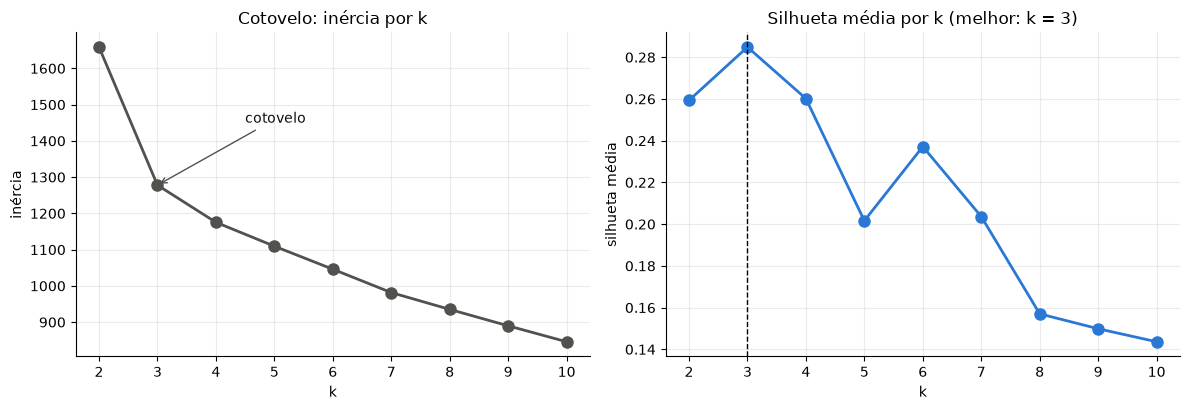

In [10]:
resultados = []
for k in range(2, 11):
    km_k = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X)
    resultados.append({"k": k, "inércia": km_k.inertia_, "silhueta": silhouette_score(X, km_k.labels_)})
resultados = pd.DataFrame(resultados).set_index("k")
resultados["queda da inércia (%)"] = -resultados["inércia"].pct_change() * 100   # queda em relação ao k anterior
with pd.option_context("display.float_format", "{:,.3f}".format):
    display(resultados)

k_melhor = resultados["silhueta"].idxmax()
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].plot(resultados.index, resultados["inércia"], "o-", color="#52514e", lw=2, ms=8)
axes[0].annotate("cotovelo", xy=(3, resultados.loc[3, "inércia"]), xytext=(4.5, 1450),
                 arrowprops=dict(arrowstyle="->", color="#52514e"), color="#0b0b0b")
axes[0].set(title="Cotovelo: inércia por k", xlabel="k", ylabel="inércia")
axes[1].plot(resultados.index, resultados["silhueta"], "o-", color=CORES_SLOTS[0], lw=2, ms=8)
axes[1].axvline(k_melhor, ls="--", color="black", lw=1)
axes[1].set(title=f"Silhueta média por k (melhor: k = {k_melhor})", xlabel="k", ylabel="silhueta média")
plt.tight_layout(); plt.show()

**Leitura:**

- **Cotovelo:** de k = 2 para k = 3 a inércia cai 23,0%. A partir daí cada grupo a mais compra pouco: 8,0% em k = 4
  e entre 4,7% e 6,2% depois. A curva "dobra" em **k = 3**;
- **Silhueta:** o máximo é **0,285, em k = 3**. Com k = 4 cai para 0,260, e de k = 5 em diante fica em 0,20 ou
  menos.

Os dois métodos apontam o mesmo k = 3. A silhueta de 0,285 é moderada: os grupos existem, mas parte dos vinhos fica
perto da fronteira (a própria aula lembra que perfis reais se sobrepõem). O gráfico de silhueta por grupo mostra
onde isso acontece.

### d.2 O gráfico de silhueta, grupo a grupo

A média esconde coisas. O `silhouette_samples` dá a silhueta de **cada vinho**. Ordenando por grupo, vemos quais são
coesos (barras largas, acima da média) e quais foram forçados (barras curtas ou negativas).

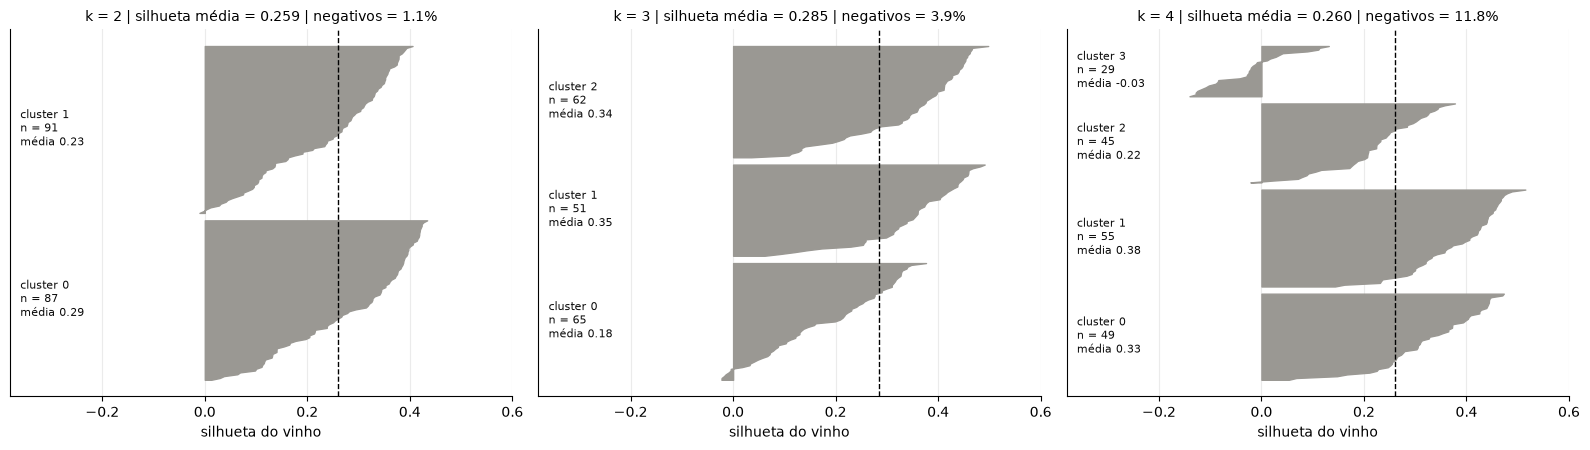

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), sharex=True)
for ax, k in zip(axes, [2, 3, 4]):
    rotulos_k = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit_predict(X)
    sil = silhouette_samples(X, rotulos_k)
    y0 = 3
    for c in range(k):
        valores = np.sort(sil[rotulos_k == c])
        ax.fill_betweenx(np.arange(y0, y0 + len(valores)), 0, valores, color="#9a9893")
        ax.text(-0.36, y0 + len(valores) / 2, f"cluster {c}\nn = {len(valores)}\nmédia {valores.mean():.2f}",
                fontsize=8, va="center", color="#0b0b0b")
        y0 += len(valores) + 3
    ax.axvline(sil.mean(), ls="--", color="black", lw=1)
    ax.set_title(f"k = {k} | silhueta média = {sil.mean():.3f} | negativos = {(sil < 0).mean():.1%}", fontsize=10)
    ax.set_yticks([]); ax.set_xlabel("silhueta do vinho"); ax.set_xlim(-0.38, 0.6)
plt.tight_layout(); plt.show()

**Leitura:**

- **k = 2:** poucos negativos, mas dois grupos grandes e de média baixa (0,23 e 0,29). Dois perfis diferentes estão
  sendo forçados a dividir o mesmo grupo;
- **k = 3:** os três grupos têm tamanho parecido e cruzam a linha da média. Dois são bem coesos (≈ 0,35); o terceiro
  é mais fraco (≈ 0,18), sinal de que parte dos vinhos dele fica perto da fronteira com outro grupo. Só 3,9% dos
  vinhos têm silhueta negativa;
- **k = 4:** aparece um grupo com silhueta média **negativa** e os negativos sobem para 11,8%. O algoritmo cortou
  ao meio um grupo que não pedia divisão.

**Decisão: k = 3**, escolhido pelo cotovelo e confirmado pela silhueta média e pelo gráfico de silhueta. A hipótese
inicial do item c.2 se sustenta.

### d.3 Modelo final

Imputação, padronização e K-Means num único `Pipeline` (como no notebook da aula). O que é aprendido no ajuste
(medianas, médias, desvios e centróides) fica guardado e é reaplicado igual a qualquer vinho novo com `predict`.

In [12]:
K_FINAL = 3

modelo = Pipeline([
    ("imputa", SimpleImputer(strategy="median")),   # sem efeito hoje (0 nulos); protege vinhos novos
    ("padroniza", StandardScaler()),                 # z-score: as 13 variáveis com o mesmo peso
    ("kmeans", KMeans(n_clusters=K_FINAL, n_init=10, random_state=SEED)),
])
vinhos["cluster"] = modelo.fit_predict(vinhos[FEATURES])

print(f"silhueta do modelo final: {silhouette_score(X, vinhos['cluster']):.3f}")
print(f"mesmos grupos do item c.2? ARI = {adjusted_rand_score(rotulos_iniciais, vinhos['cluster']):.3f}")
vinhos["cluster"].value_counts().sort_index().rename("vinhos por cluster")

silhueta do modelo final: 0.285
mesmos grupos do item c.2? ARI = 1.000


cluster
0    65
1    51
2    62
Name: vinhos por cluster, dtype: int64

## e) Análise dos grupos e das características dos vinhos

### e.1 Perfil médio de cada grupo

O K-Means devolve números (0, 1, 2). Quem transforma número em **grupo com nome** é a leitura do perfil nas
**unidades originais**, comparando cada grupo com a média geral.

In [13]:
perfil = vinhos.groupby("cluster")[FEATURES].mean()
perfil.insert(0, "vinhos", vinhos["cluster"].value_counts().sort_index())
perfil.insert(1, "% dos vinhos", perfil["vinhos"] / len(vinhos) * 100)

# A numeração dos clusters pode mudar de uma versão do scikit-learn para outra. Por isso o nome
# de cada grupo sai de regras lidas no perfil, uma de cada vez (como no notebook da aula):
#   1) maior teor alcoólico          -> "Encorpados"
#   2) dos restantes, mais ácido     -> "Ácidos"
#   3) o que sobrar                  -> "Leves"
restantes, nomes = list(perfil.index), {}
for nome, coluna in [("Encorpados", "Alcohol"), ("Ácidos", "Malic_Acid")]:
    escolhido = perfil.loc[restantes, coluna].idxmax()
    nomes[escolhido] = nome
    restantes.remove(escolhido)
nomes[restantes[0]] = "Leves"

ORDEM = ["Encorpados", "Ácidos", "Leves"]
CORES = dict(zip(ORDEM, CORES_SLOTS))         # cada grupo tem sempre a mesma cor nos gráficos
vinhos["grupo"] = vinhos["cluster"].map(nomes)

perfil_nomeado = perfil.rename(index=nomes).loc[ORDEM]
perfil_nomeado.loc["MÉDIA GERAL"] = [len(vinhos), 100.0] + vinhos[FEATURES].mean().tolist()
perfil_nomeado.T

cluster,Encorpados,Ácidos,Leves,MÉDIA GERAL
vinhos,62.00,51.00,65.00,178.00
% dos vinhos,34.83,28.65,36.52,100.00
Alcohol,13.68,13.13,12.25,13.00
Malic_Acid,2.00,3.31,1.90,2.34
Ash,2.47,2.42,2.23,2.37
Ash_Alcanity,17.46,21.24,20.06,19.49
Magnesium,107.97,98.67,92.74,99.74
Total_Phenols,2.85,1.68,2.25,2.30
Flavanoids,3.00,0.82,2.05,2.03
Nonflavanoid_Phenols,0.29,0.45,0.36,0.36


**Leitura:** cada grupo tem uma assinatura química própria. Os nomes vêm das duas perguntas do enunciado (álcool e
acidez), e os itens a seguir detalham cada característica.

### e.2 Qual o teor alcoólico dos vinhos de cada grupo?

,média,mediana,mínimo,máximo,CV (%),vinhos com ≥ 14%
grupo,,,,,,
Encorpados,13.68,13.73,11.56,14.83,4.09,19
Ácidos,13.13,13.11,12.20,14.34,3.97,3
Leves,12.25,12.25,11.03,13.86,4.35,0


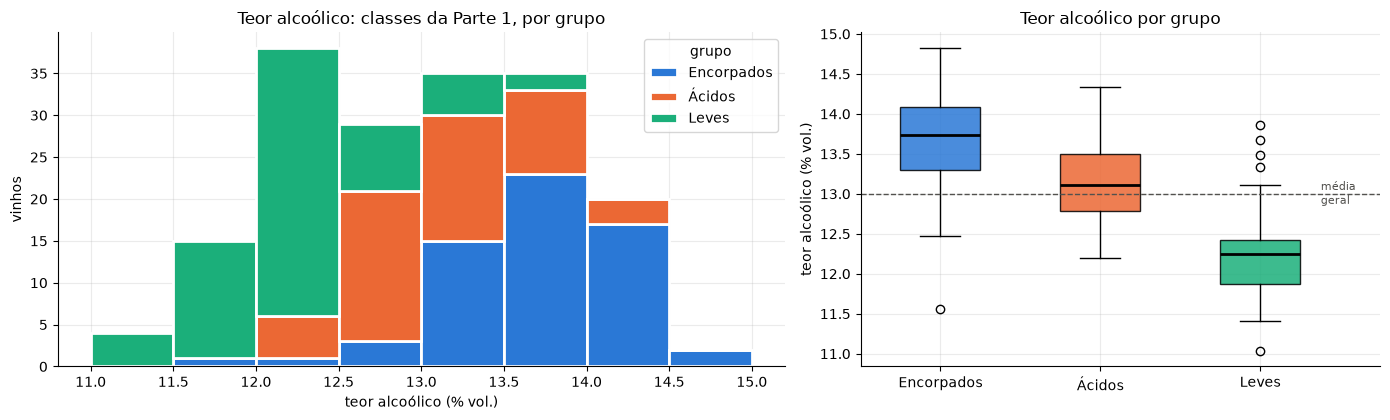

In [14]:
def resumo(coluna):
    # Tendência central, dispersão e faixa por grupo: as mesmas medidas da Parte 1
    g = vinhos.groupby("grupo")[coluna]
    return pd.DataFrame({"média": g.mean(), "mediana": g.median(), "mínimo": g.min(),
                         "máximo": g.max(), "CV (%)": g.std() / g.mean() * 100}).loc[ORDEM]

def grafico_por_grupo(coluna, limites, rotulo, titulo):
    # Esquerda: histograma com as MESMAS classes da Parte 1, empilhado por grupo.
    # Direita: boxplot por grupo (a Parte 1 fez um boxplot só, com todos os vinhos).
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.3), gridspec_kw={"width_ratios": [1.4, 1]})
    ax1.hist([vinhos.loc[vinhos["grupo"] == g, coluna] for g in ORDEM], bins=limites, stacked=True,
             color=[CORES[g] for g in ORDEM], label=ORDEM, edgecolor="white", linewidth=2)
    ax1.set(xticks=limites, xlabel=rotulo, ylabel="vinhos", title=f"{titulo}: classes da Parte 1, por grupo")
    ax1.legend(title="grupo")
    caixas = ax2.boxplot([vinhos.loc[vinhos["grupo"] == g, coluna] for g in ORDEM], tick_labels=ORDEM,
                         patch_artist=True, widths=0.5, medianprops=dict(color="black", lw=2))
    for caixa, g in zip(caixas["boxes"], ORDEM):
        caixa.set(facecolor=CORES[g], alpha=0.85)
    ax2.axhline(vinhos[coluna].mean(), ls="--", color="#52514e", lw=1)
    ax2.text(3.38, vinhos[coluna].mean(), "média\ngeral", va="center", fontsize=8, color="#52514e")
    ax2.set(xlim=(0.5, 3.75), ylabel=rotulo, title=f"{titulo} por grupo")
    plt.tight_layout(); plt.show()

alcool = resumo("Alcohol")
alcool["vinhos com ≥ 14%"] = vinhos[vinhos["Alcohol"] >= 14].groupby("grupo").size().reindex(ORDEM, fill_value=0)
display(alcool)
grafico_por_grupo("Alcohol", np.arange(11, 15.01, 0.5), "teor alcoólico (% vol.)", "Teor alcoólico")

**Leitura:**

- **Encorpados:** o maior teor alcoólico, com média de **13,68%** e mediana de 13,73%. Concentra 19 dos 22 vinhos com
  14% ou mais. Na Parte 1, a Normal previa P(X ≥ 14) ≈ 10,92%, um evento pouco provável. Agora sabemos onde esses
  vinhos estão: quase todos neste grupo;
- **Ácidos:** teor intermediário, média de **13,13%**, perto da média geral (13,00%);
- **Leves:** o menor teor alcoólico, média de **12,25%**. Nenhum vinho deste grupo chega a 14%.

**H1 confirmada.** O histograma da esquerda é o da Parte 1, agora pintado por grupo. O primeiro pico, em
[12 ; 12,5), é formado quase só pelos vinhos Leves. O segundo, em [13 ; 14), pelos Encorpados e Ácidos. A
bimodalidade vista na Parte 1 era a mistura de grupos com teores alcoólicos típicos diferentes.

Repare ainda no CV: no conjunto todo ele era 6,24% (Parte 1); **dentro** de cada grupo cai para cerca de 4%. Boa
parte da variação do álcool é diferença **entre** grupos.

### e.3 Qual o grupo com vinhos mais ácidos?

,média,mediana,mínimo,máximo,CV (%),vinhos com > 3 g/L,% dos vinhos > 3 g/L
grupo,,,,,,,
Encorpados,2.00,1.77,1.35,4.04,33.82,7,14.89
Ácidos,3.31,3.27,1.24,5.65,33.06,32,68.09
Leves,1.90,1.61,0.74,5.80,53.35,8,17.02


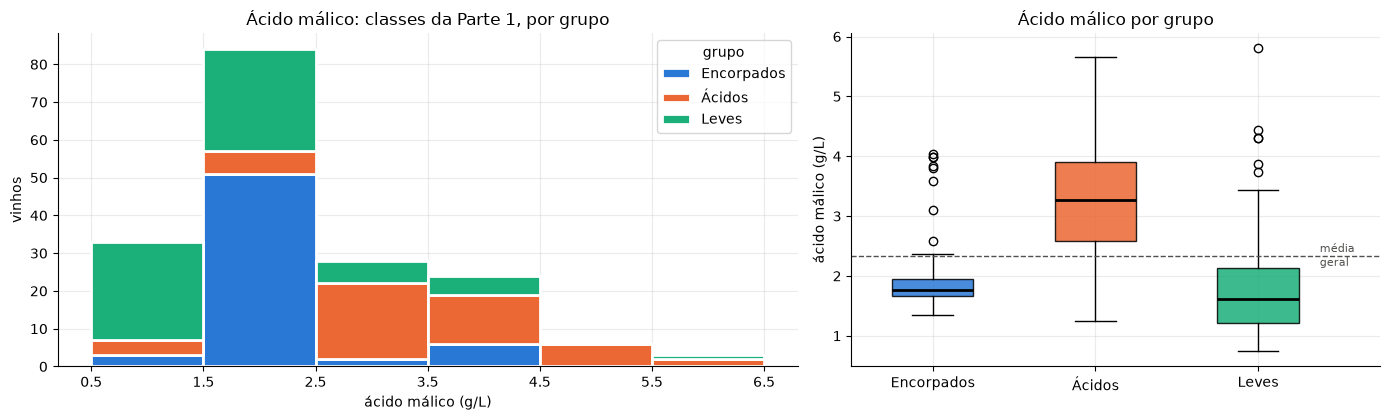

,Malic_Acid,Alcohol,Flavanoids,Color_Intensity,Hue,Proline,grupo
123,5.80,13.05,2.65,2.60,0.73,380,Leves
137,5.51,12.53,0.60,5.00,0.82,515,Ácidos
173,5.65,13.71,0.61,7.70,0.64,740,Ácidos


In [15]:
acido = resumo("Malic_Acid")
acido["vinhos com > 3 g/L"] = vinhos[vinhos["Malic_Acid"] > 3].groupby("grupo").size().reindex(ORDEM, fill_value=0)
acido["% dos vinhos > 3 g/L"] = acido["vinhos com > 3 g/L"] / (vinhos["Malic_Acid"] > 3).sum() * 100
display(acido)
grafico_por_grupo("Malic_Acid", np.arange(0.5, 6.51, 1), "ácido málico (g/L)", "Ácido málico")

# Onde foram parar os 3 outliers de ácido málico da Parte 1?
vinhos.loc[eh_outlier["Malic_Acid"], ["Malic_Acid", "Alcohol", "Flavanoids", "Color_Intensity", "Hue", "Proline", "grupo"]]

**Leitura:**

- O grupo **Ácidos** é o mais ácido: média de **3,31 g/L** e mediana de 3,27 g/L, contra 2,00 g/L nos Encorpados e
  1,90 g/L nos Leves. Metade dos vinhos dele passa de 3,27 g/L;
- Dos 47 vinhos com mais de 3 g/L, 32 (68%) estão no grupo Ácidos;
- Dos 3 outliers da Parte 1, dois (5,51 e 5,65 g/L) estão no grupo Ácidos. O mais ácido de todos (5,80 g/L) caiu
  no grupo **Leves**: no resto das medidas (cor clara, de 2,60; prolina muito baixa, de 380; flavonoides perto da
  média) ele se parece com os Leves. O K-Means olha as 13 variáveis juntas, não só a acidez.

**H2 confirmada em parte.** Existe, sim, um grupo mais ácido. Mas ele não é "o grupo dos vinhos acima de 3 g/L": 15
desses vinhos ficaram em outros grupos, e o grupo Ácidos também tem vinhos com só 1,24 g/L. O que define o grupo é uma
combinação de variáveis, como mostra o item e.4.

### e.4 Cinzas e o que mais diferencia um grupo do outro

,média,mediana,mínimo,máximo,CV (%)
grupo,,,,,
Encorpados,2.47,2.45,2.04,3.23,9.95
Ácidos,2.42,2.38,1.98,2.86,8.23
Leves,2.23,2.24,1.36,2.92,13.41


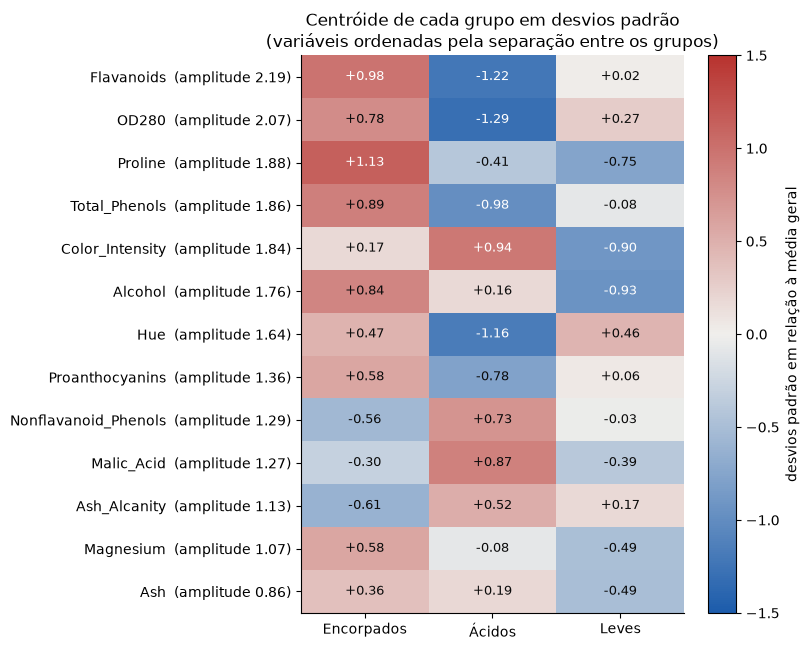

In [16]:
display(resumo("Ash"))

# Centróides em desvios padrão (z): 0 = média geral, +1 = um desvio acima. Como todas as variáveis
# estão na mesma escala, a "amplitude" (maior z - menor z) mede quanto cada variável separa os grupos.
z = pd.DataFrame(X, columns=FEATURES).groupby(vinhos["grupo"].to_numpy()).mean().loc[ORDEM].T
z["amplitude"] = z.max(axis=1) - z.min(axis=1)
z = z.sort_values("amplitude", ascending=False)

DIVERGENTE = LinearSegmentedColormap.from_list("azul_cinza_vermelho", ["#1c5cab", "#f0efec", "#b8332f"])
fig, ax = plt.subplots(figsize=(8, 6.6))
im = ax.imshow(z[ORDEM], cmap=DIVERGENTE, vmin=-1.5, vmax=1.5, aspect="auto")
for i, variavel in enumerate(z.index):
    for j, g in enumerate(ORDEM):
        valor = z.loc[variavel, g]
        ax.text(j, i, f"{valor:+.2f}", ha="center", va="center", fontsize=9,
                color="white" if abs(valor) > 0.9 else "#0b0b0b")
ax.set_xticks(range(len(ORDEM)), ORDEM)
ax.set_yticks(range(len(z)), [f"{v}  (amplitude {a:.2f})" for v, a in zip(z.index, z["amplitude"])])
ax.grid(False)
fig.colorbar(im, ax=ax, label="desvios padrão em relação à média geral")
ax.set_title("Centróide de cada grupo em desvios padrão\n(variáveis ordenadas pela separação entre os grupos)")
plt.tight_layout(); plt.show()

**Leitura das cinzas:** o grupo **Leves** tem menos cinzas (média de 2,23, contra 2,42 e 2,47 nos outros). Os
Encorpados têm a maior média (2,47). Mas a diferença é pequena: `Ash` é a variável que **menos** separa os grupos
(amplitude de 0,86 desvio, a última do mapa).

**O que mais diferencia os grupos** (topo do mapa de calor): flavonoides, OD280, prolina, fenóis totais,
intensidade de cor, teor alcoólico e tonalidade. O ácido málico aparece só em **10º lugar** (amplitude de 1,27).

**H3 não se confirmou.** A Parte 1 esperava que a acidez fosse o que mais diferencia os grupos, por ter o CV mais
alto. A tabela abaixo explica por que isso não aconteceu.

In [17]:
# CV no conjunto todo (Parte 1) x CV dentro de cada grupo
cv_geral = vinhos[["Alcohol", "Malic_Acid"]].std() / vinhos[["Alcohol", "Malic_Acid"]].mean() * 100
cv_grupos = vinhos.groupby("grupo")[["Alcohol", "Malic_Acid"]].agg(lambda s: s.std() / s.mean() * 100).T[ORDEM]
cv_grupos.insert(0, "CV geral (Parte 1)", cv_geral)
cv_grupos.rename_axis("CV (%)")

grupo,CV geral (Parte 1),Encorpados,Ácidos,Leves
CV (%),,,,
Alcohol,6.24,4.09,3.97,4.35
Malic_Acid,47.82,33.82,33.06,53.35


**Leitura:** o CV mede quanto uma variável se espalha, mas não diz **onde** está o espalhamento.

- No **álcool**, o CV cai de 6,24% para cerca de 4% dentro dos grupos: boa parte da variação está **entre** os
  grupos, e por isso o álcool ajuda a separá-los;
- No **ácido málico**, o CV continua alto dentro de cada grupo (33% a 53%): a variação está **dentro** dos grupos
  (a cauda longa e os outliers da Parte 1 aparecem nos três). Um CV alto não garante que a variável separe grupos.

### e.5 Visualizando os grupos em 2D com PCA

O K-Means rodou nas 13 dimensões. O `PCA` só projeta o resultado num plano para podermos olhar (como na aula).

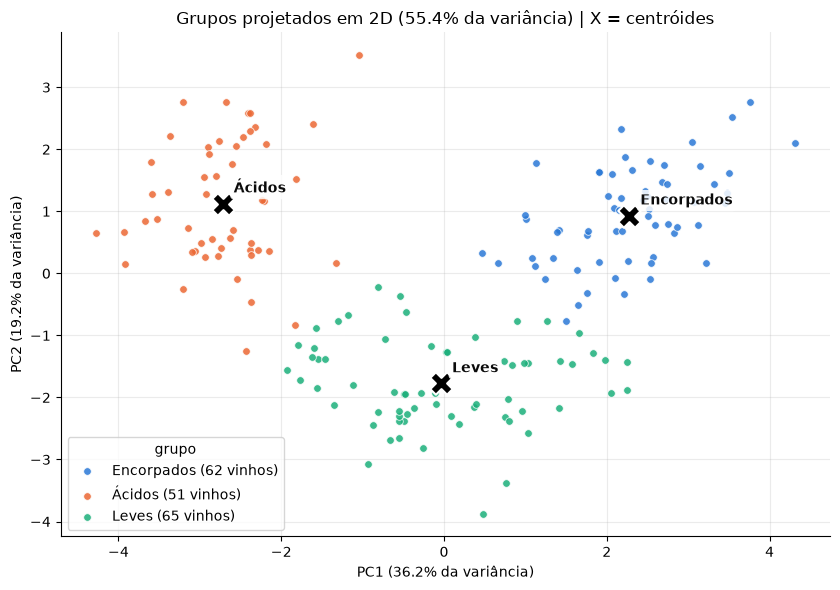

In [18]:
pca = PCA(n_components=2, random_state=SEED)
Z = pca.fit_transform(X)
centroides_2d = pca.transform(modelo.named_steps["kmeans"].cluster_centers_)
var = pca.explained_variance_ratio_

fig, ax = plt.subplots(figsize=(8.5, 6))
for g in ORDEM:
    m = (vinhos["grupo"] == g).to_numpy()
    ax.scatter(Z[m, 0], Z[m, 1], s=30, alpha=0.85, color=CORES[g], edgecolor="white", linewidth=0.6,
               label=f"{g} ({m.sum()} vinhos)")
for c, (x, y) in enumerate(centroides_2d):
    ax.scatter(x, y, marker="X", s=260, c="black", edgecolor="white", lw=1.5)
    ax.annotate(nomes[c], (x, y), xytext=(8, 8), textcoords="offset points", fontsize=10,
                fontweight="bold", color="#0b0b0b",
                bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="none", alpha=0.85))
ax.set(xlabel=f"PC1 ({var[0]:.1%} da variância)", ylabel=f"PC2 ({var[1]:.1%} da variância)",
       title=f"Grupos projetados em 2D ({var.sum():.1%} da variância) | X = centróides")
ax.legend(title="grupo")
plt.tight_layout(); plt.show()

**Leitura:** mesmo achatados em 2 dimensões, os três grupos aparecem como três nuvens com pouca sobreposição. Os
Encorpados e os Ácidos ficam nos extremos do primeiro eixo, e os Leves se separam no segundo eixo. A sobreposição
que existe fica na fronteira dos Leves, o que bate com a silhueta mais baixa desse grupo no item d.2.

### e.6 Ficha de cada grupo

| Grupo | Vinhos | Álcool | Acidez | Cinzas | Outras marcas |
|---|---|---|---|---|---|
| **1 · Encorpados** | 62 (34,8%) | **maior** (13,68%) | baixa (2,00 g/L) | **mais cinzas** (2,47) | muita prolina (1.100, quase 1,5× a média), os mais ricos em flavonoides (3,00), fenóis totais e OD280; mais magnésio; menor alcalinidade das cinzas |
| **2 · Ácidos** | 51 (28,7%) | médio (13,13%) | **a maior** (3,31 g/L) | médias (2,42) | cor mais **intensa** (7,23) e tonalidade mais baixa (0,69); os **mais pobres** em flavonoides (0,82), fenóis totais e OD280; mais fenóis não flavonoides |
| **3 · Leves** | 65 (36,5%) | **menor** (12,25%) | a menor (1,90 g/L) | **menos cinzas** (2,23) | cor mais **clara** (2,97), a menor prolina (510) e o menor magnésio; flavonoides e fenóis perto da média |

No formato do exemplo do enunciado:

- **Grupo 1 · Encorpados:** vinhos com o maior teor alcoólico, pouco ácidos, com mais cinzas, muita prolina e muito
  ricos em compostos fenólicos (flavonoides);
- **Grupo 2 · Ácidos:** vinhos mais ácidos, com teor alcoólico médio, cor intensa e tonalidade baixa, e com poucos
  flavonoides;
- **Grupo 3 · Leves:** vinhos com o menor teor alcoólico, menos ácidos, com pouca cinza, cor clara e pouca prolina.

## Validação: abrindo o cofre

Na aula, a base era sintética e no fim "abrimos o cofre" para conferir se o K-Means tinha recuperado os perfis
escondidos. Aqui dá para fazer o mesmo: a versão original da base (UCI) tem o **cultivar** de cada vinho, e ela vem
embutida no scikit-learn como `load_wine`, com os mesmos 178 vinhos na mesma ordem.

**O cultivar não foi usado em nenhum momento do modelo.** Ele entra só agora, para avaliar o resultado.

In [19]:
from sklearn.datasets import load_wine     # importado só aqui: o rótulo não participa do modelo

original = load_wine(as_frame=True)
print("mesmos valores e mesma ordem do nosso CSV:", np.allclose(original.data.to_numpy(), vinhos[FEATURES].to_numpy()))

cultivar = original.target.map({0: "cultivar 1", 1: "cultivar 2", 2: "cultivar 3"}).rename("cultivar real")
display(pd.crosstab(cultivar, vinhos["grupo"])[ORDEM])
print(f"ARI contra o cultivar: {adjusted_rand_score(cultivar, vinhos['grupo']):.3f}")

mesmos valores e mesma ordem do nosso CSV: True


grupo,Encorpados,Ácidos,Leves
cultivar real,,,
cultivar 1,59,0,0
cultivar 2,3,3,65
cultivar 3,0,48,0


ARI contra o cultivar: 0.897


**Leitura:** cada grupo corresponde a um cultivar. Os Encorpados são o cultivar 1, os Ácidos o cultivar 3 e os Leves
o cultivar 2. Só 6 dos 178 vinhos (3,4%), todos do cultivar 2, caíram em outro grupo, e o ARI é de **0,897**. Sem ver
nenhum rótulo, o K-Means reencontrou os três tipos de uva só pelas medidas químicas. Isso também explica a silhueta
mais baixa dos Leves: é o grupo do cultivar 2, o que tem vinhos na fronteira com os outros dois.

### O experimento da aula: silhueta alta não garante agrupamento certo

Refazemos o experimento do slide "A armadilha" com outros pré-processamentos, inclusive o cenário simplificado com
só as duas variáveis da Parte 1.

In [20]:
cenarios = {
    "13 variáveis + StandardScaler (escolhido)": StandardScaler().fit_transform(vinhos[FEATURES]),
    "13 variáveis + MinMaxScaler": MinMaxScaler().fit_transform(vinhos[FEATURES]),
    "13 variáveis sem padronizar": vinhos[FEATURES].to_numpy(),
    "só Alcohol + Malic_Acid (Parte 1), padronizadas": StandardScaler().fit_transform(vinhos[["Alcohol", "Malic_Acid"]]),
}
linhas = []
for nome, Xc in cenarios.items():
    rotulos_c = KMeans(n_clusters=3, n_init=10, random_state=SEED).fit_predict(Xc)
    linhas.append({"cenário": nome,
                   "silhueta (no próprio espaço)": silhouette_score(Xc, rotulos_c),
                   "ARI contra o cultivar": adjusted_rand_score(cultivar, rotulos_c)})
with pd.option_context("display.float_format", "{:,.3f}".format):
    display(pd.DataFrame(linhas).set_index("cenário"))

,silhueta (no próprio espaço),ARI contra o cultivar
cenário,,
13 variáveis + StandardScaler (escolhido),0.285,0.897
13 variáveis + MinMaxScaler,0.301,0.854
13 variáveis sem padronizar,0.571,0.371
"só Alcohol + Malic_Acid (Parte 1), padronizadas",0.484,0.444


**Leitura:**

- **Sem padronizar**, a silhueta **sobe** para 0,571, mas o ARI **despenca** para 0,371. É a armadilha da aula: a
  silhueta é calculada no espaço em que o K-Means rodou, e sem padronização esse espaço é praticamente só a prolina.
  Ali é fácil formar grupos compactos, mas eles ignoram as outras 12 variáveis;
- **Só álcool e acidez** (as variáveis da Parte 1): silhueta de 0,484 e ARI de 0,444. Simplificar demais perde a
  estrutura. As duas variáveis sozinhas não separam os cultivares (como já se via no item c.1), porque o que mais
  diferencia os grupos são os compostos fenólicos e a prolina;
- **`MinMaxScaler`** funciona (ARI de 0,854), mas fica abaixo do `StandardScaler` (0,897), como esperávamos no item
  b.5. Repare que a silhueta dele é maior (0,301 contra 0,285), e mesmo assim o agrupamento é pior.

**Regra da aula:** métricas internas (silhueta, inércia) servem para comparar soluções **no mesmo espaço** (k = 3
contra k = 4). Não servem para comparar pré-processamentos ou conjuntos de variáveis diferentes. Por isso o k foi
escolhido pela silhueta, e o pré-processamento pelo raciocínio do item b, que o gabarito só confirmou.

## Conclusão

**O que foi feito.** Usamos a mesma base da Parte 1, sem features de classe, nulos ou duplicados. Mantivemos os
outliers, e conferimos que eles não mudam os grupos (ARI = 1,000). Padronizamos as 13 variáveis, porque sem isso a
prolina sozinha responderia por 99,77% da distância. Ajustamos o K-Means com `k-means++` e `n_init=10` dentro de um
`Pipeline`. O cotovelo e a silhueta apontaram o mesmo número de grupos: **k = 3** (silhueta de 0,285).

**Os três grupos:**

| Grupo | Teor alcoólico | Acidez (ácido málico) | Cinzas | Assinatura |
|---|---|---|---|---|
| **Encorpados** | o maior (13,68%) | baixa (2,00 g/L) | as maiores (2,47) | muita prolina e flavonoides |
| **Ácidos** | médio (13,13%) | **a maior** (3,31 g/L) | médias (2,42) | cor intensa, poucos flavonoides |
| **Leves** | o menor (12,25%) | a menor (1,90 g/L) | as menores (2,23) | cor clara, pouca prolina |

**Ligação com a Parte 1:**

- **H1 confirmada:** a bimodalidade do teor alcoólico era a mistura de grupos. O pico em [12 ; 12,5) é dos Leves, e
  o pico em [13 ; 14) é dos Encorpados e Ácidos. Os vinhos com 14% ou mais, raros pela Normal da Parte 1 (≈ 11%),
  estão quase todos nos Encorpados;
- **H2 confirmada em parte:** existe um grupo mais ácido, com 68% dos vinhos acima de 3 g/L, mas ele é definido por
  várias variáveis juntas, não só pela acidez;
- **H3 não confirmada:** o ácido málico tem o maior CV, mas a variação dele está dentro dos grupos. Quem mais separa
  os vinhos são os flavonoides, o OD280, a prolina, os fenóis, a cor e o próprio teor alcoólico. Variabilidade alta
  não é o mesmo que poder de separação.

**Validação:** comparando com o cultivar real (que o modelo nunca viu), cada grupo corresponde a um tipo de uva, com
ARI de 0,897. Só 6 dos 178 vinhos ficaram fora do grupo do seu cultivar.

**Limites:** o K-Means assume grupos compactos e mais ou menos esféricos, é sensível à escala (por isso
padronizamos) e sempre devolve k grupos, mesmo que não exista estrutura. A silhueta moderada (0,285) mostra que
alguns vinhos, principalmente do grupo Leves, ficam na fronteira entre dois grupos.